In [1]:
import os
#import argparse
#parser=argparse.ArgumentParser(description='trim video into short piece')
#parser.add_argument('-i','--input_path',help='path to the video as a string: eg. C:/Users/../, apostrophe not shown',type=str,default='Z:/DATA/experiment_trackball_Optomotor')
#parser.add_argument('-n','--exp_name',help='the stimulus name of the experiment: eg. xxx, apostrophe not shown',type=str,default='gratings')
#parser.add_argument('-d','--exp_date',help='the date of the experiment',type=list,default=['220712','220714'])
#args= parser.parse_args()
#def create_data_list(input_path, exp_name, exp_date):
data_list=[]
input_path = 'Z:/DATA/experiment_trackball_Optomotor'
dataset=os.listdir(input_path)
exp_date=['220813','220811','220814']
exp_name='sweeploom'
for locust in dataset:
    locust_directory=input_path + '/' + locust
    file_list = os.listdir(locust_directory)
    for thisDate in file_list:
        if thisDate in exp_date:
            experiment_directory=locust_directory + '/' + thisDate
            experiment_list=os.listdir(experiment_directory)
            for thisExperiment in experiment_list:
                if thisExperiment in exp_name:
                    data_list.append(experiment_directory + '/' + exp_name)
#    return data_list

#if __name__ == '__main__':
#    create_data_list(args.input_path,args.exp_name,args.exp_date)

In [110]:
##The meta information of the stimulus is now included in each cell when the stimulus is delivered
##They are saved as stim_variable object.
##For gratings: it only includs temporal frequency at the moment 2022 sep 6th
##For sweeploom: it includs the initial and ending size; initial and ending position, by this order 
##For sweeploom: it includs stimid, size, Colour1, numDots1, Contrast1, VelX1, Coherence1 by this order 
import os, fnmatch
import pandas as pd
import numpy as np
import re
def generate_curated_database(myList = [], *args):
    overwrite_file=True
    save_file=True
    #csv_pattern='trial_*.csv'
    dat_pattern='*.dat'    
    track_ball_radius=4
    frame_rate=144
    #stim_duration = 25 # in sec
    #grey_duration = 5
    for thisDir in myList:
        # list up the files in the dir
        file = os.listdir(thisDir)
        # look for files that matches the pattern
        dat_file= fnmatch.filter(file, dat_pattern)
        dat_file_directory= os.path.join(thisDir ,dat_file[0])

   
        ## load dat file
    
        raw_data = pd.read_table(dat_file_directory, sep="\s+")
        ## fictrac title is here 'frame counter', 'delta rotation vector cam x', 'delta rotation vector cam y', \
        ##'delta rotation vector cam z', 'delta rotation error score', 'delta rotation vector lab x', \
        ##'delta rotation vector lab y', 'delta rotation vector lab z', 'absolute rotation vector cam x',\
        ##'absolute rotation vector cam y', 'absolute rotation vector cam z', \
        ##'absolute rotation vector lab x', 'absolute rotation vector lab y', \
        ##'absolute rotation vector lab z', 'intergrated x position','intergrated y position', \
        ##'intergrated animal heading', 'animal movement direction', 'animal movement speed', \
        ##'intergrated forward motion','intergrated side motion', 'timestamp', 'sequence counter','delta timestamp', 'alt. timestamp']

        ## drop some column
        raw_data.drop(raw_data.columns[[0,1,2,3,4,8,9,10,16,17,19,20,21,22,23]], axis=1, inplace=True)
        raw_data.columns=['delta rotation vector lab x', 'delta rotation vector lab y', 'delta rotation vector lab z',                       'absolute rotation vector lab x', 'absolute rotation vector lab y', 'absolute rotation vector lab z',                       'intergrated x position','intergrated y position','instant speed','timestamp']
        ## cleaning , and change the data from object to float
        raw_data.iloc[:, :]=raw_data.iloc[:, :].replace({',': ''}, regex= True)
        for ind in range(0, raw_data.shape[1]):
            raw_data.iloc[:, ind]=pd.to_numeric(raw_data.iloc[:, ind]).astype('float32')
        
        ## adjust the unit of the x, y position
        raw_data.iloc[:, 6]=raw_data.iloc[:, 6]*track_ball_radius
        raw_data.iloc[:, 7]=raw_data.iloc[:, 7]*track_ball_radius
        raw_data.iloc[:, 8]=raw_data.iloc[:, 8]*track_ball_radius
        ## adjust the unit of the z vector based on the target frame rate of fictrac
        raw_data.iloc[:, 2]=raw_data.iloc[:, 2]*frame_rate
  
        ### save the curated_database
        if save_file==True:
            database_name='database_curated.pickle'
            database_directory= os.path.join(thisDir,database_name)
            if (overwrite_file ==False) and (os.path.isfile == True):
                continue
            else:
                raw_data.to_pickle(database_directory)

In [112]:
generate_curated_database(data_list)

In [186]:
import os, fnmatch
import pandas as pd
import numpy as np
import re
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
csv_pattern='trial_*.csv'
database_pattern='*.pickle'
exp_name='sweeploom'
frame_rate=144
stim_duration=4
grey_duration=1
analysis_window=frame_rate*(stim_duration+grey_duration)
stim_type=["b2f_l_sweep","f2b_l_sweep","b2f_l_sloom","f2b_l_sloom","f2b_r_sweep","b2f_r_sweep","f2b_r_sloom","b2f_r_sloom"]

In [199]:
sg_filering= True
analyse_every_trial = False
plotting_trajectory = False
plotting_event_related_trajectory = True
stim_of_interest=stim_type[4]
#for thisDir in myList:

In [200]:
file = os.listdir(thisDir)
file_name= fnmatch.filter(file, database_pattern)
database= os.path.join(thisDir,file_name[0])
df=pd.read_pickle(database)
if sg_filering == True:
    x_all = savgol_filter(df.loc[:, ['intergrated x position']], 99, 3, axis=0)
    y_all = savgol_filter(df.loc[:, ['intergrated y position']], 99, 3, axis=0)
    instant_v=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
    #vx=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
    #vz=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
else:
    x_all = df.loc[:, ['intergrated x position']]
    y_all = df.loc[:, ['intergrated y position']]

if plotting_trajectory == True:
    plt.plot(x_all, y_all,c=np.arange(len(y_all)), marker='.', alpha=0.5)
    plt.show()   

csv_file= fnmatch.filter(file, csv_pattern)
csv_file_directory= os.path.join(thisDir ,csv_file[0])    
stim_info = pd.read_csv(csv_file_directory)
stim_info=stim_info.reset_index()
stim_variable=[]
stimulus_timestamp=[]

if exp_name == 'gratings':
    for row in range(0, len(stim_info)):
    #delete the bracket in current speed and save it as integer in new list
        stim_variable.append(int(stim_info.loc[row, 'Frame'].replace('(', '')))
    # combine the last two values into the timestamp (were divided into 2 columns cause german computer
    # used comma as decimal seperator and save timestamp as float in new file
        if isinstance(stim_info.loc[row, 'Value'], float):
            timestamp = stim_info.loc[row, 'Timestamp']
        else:
            timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
        stimulus_timestamp.append(float(timestamp.replace(')', '')))
    stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))

elif exp_name == 'sweeploom':
    for row in range(0, len(stim_info)):
        stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,3].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
        stim_variable.append(int(re.split(r'=|}',stim_info.iloc[row,5])[1]))
        if isinstance(stim_info.loc[row, 'Value'], float):
            timestamp = stim_info.loc[row, 'Timestamp']
        else:
            timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
        stimulus_timestamp.append(float(timestamp.replace(')', '')))
    stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
    #some bugs in the bonsai workflow. Needs to remove the first timestamp and the last row of stim variable here
    stimulus_timestamp.pop(0)
    stim_variable=np.delete(stim_variable, -1, axis=0)
elif exp_name == 'dots':
    for row in range(0, len(stim_info)):
        stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,5].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,11].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,13].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,17].split("=",1)[1]))
        if isinstance(stim_info.loc[row, 'Value'], float):
            timestamp = stim_info.loc[row, 'Timestamp']
        else:
            timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
        stimulus_timestamp.append(float(timestamp.replace(')', '')))
    stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
else:
    warnings.warn('stimulus paradigm can not be recognised')

stim_df=pd.DataFrame(stim_variable)    

    # compare the timestamp between event file and dat file
data_timestamp=df.loc[:, 'timestamp']
stimulus_timestamp_b=np.tile(stimulus_timestamp,(len(data_timestamp),1))
data_timestamp_b=np.tile(data_timestamp,(len(stimulus_timestamp),1))
timestamp_diff= data_timestamp_b > np.transpose(stimulus_timestamp_b)
stim_onset= np.where(np.roll(timestamp_diff,1,axis=1)!=timestamp_diff)[1][1::2]
stim_df["stim_onset"]=stim_onset

filters=[(stim_df.iloc[:,0]==stim_df.iloc[:,1]) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]) & (stim_df.iloc[:,2] > 0),
(stim_df.iloc[:,0]==stim_df.iloc[:,1]) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]) & (stim_df.iloc[:,2] > 0),
(stim_df.iloc[:,0] < stim_df.iloc[:,1]) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]) & (stim_df.iloc[:,2] > 0),
(stim_df.iloc[:,0] < stim_df.iloc[:,1]) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]) & (stim_df.iloc[:,2] > 0),
(stim_df.iloc[:,0]==stim_df.iloc[:,1]) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]) & (stim_df.iloc[:,2] < 0),
(stim_df.iloc[:,0]==stim_df.iloc[:,1]) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]) & (stim_df.iloc[:,2] < 0),
(stim_df.iloc[:,0] < stim_df.iloc[:,1]) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]) & (stim_df.iloc[:,2] < 0),
(stim_df.iloc[:,0] < stim_df.iloc[:,1]) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]) & (stim_df.iloc[:,2] < 0)]

### add new column here to store event info
#         raw_data['frame_rate']=frame_rate
#         if isinstance(frame_rate, int):
#             raw_data['frame_rate']=raw_data['frame_rate'].astype('int16')  
#         elif isinstance(frame_rate, int):
#             raw_data['frame_rate']=raw_data['frame_rate'].astype('float16')

stim_df["stim_type"]=np.select(filters, stim_type)
if analyse_every_trial==True:
    stim_to_analyse=stim_df.loc[:,'stim_onset']
    stim_name_list=np.array(stim_df["stim_type"])
#elif: 'myVar' in locals():
else:
    #stim_to_analyse=stim_df.loc[np.where(stim_df.loc[:,'stim_type']==stim_of_interest),"stim_onset"]
    #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "f2b_l_sweep") | (stim_df.loc[:,'stim_type']== "f2b_r_sweep")),"stim_onset"]
    #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "b2f_l_sweep") | (stim_df.loc[:,'stim_type']== "b2f_r_sweep")),"stim_onset"]
    #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "b2f_l_sloom") | (stim_df.loc[:,'stim_type']== "b2f_r_sloom")),"stim_onset"]
    stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "f2b_l_sloom") | (stim_df.loc[:,'stim_type']== "f2b_r_sloom")),"stim_onset"]
    stim_name_list=stim_df.loc[stim_to_analyse.index,'stim_type'].values
if len(stim_to_analyse) ==0:
    print('no_required_stim_type')
    #continue

grey_onset=stim_to_analyse-np.ones(len(stim_to_analyse),dtype=int)*grey_duration*frame_rate
analysie_window_tile=np.tile(np.arange(analysis_window),(len(grey_onset),1))
index_points=np.array(grey_onset).reshape(len(grey_onset),1)+analysie_window_tile
x=x_all[index_points]
y=y_all[index_points]
x_dif=np.diff(x,axis=1)
y_dif=np.diff(y,axis=1)
travel_distance=np.sum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
vx=df.loc[:, ['delta rotation vector lab x']].values
velocity_x=vx[index_points]
vz=df.loc[:, ['delta rotation vector lab z']].values
velocity_z=vz[index_points]
#instant_v=df.loc[:, ['instant speed']].values
velocity=instant_v[index_points]
tp=np.linspace(0,stim_duration+grey_duration,velocity.shape[1])
tp_tile=np.tile(tp,(velocity.shape[0],1))

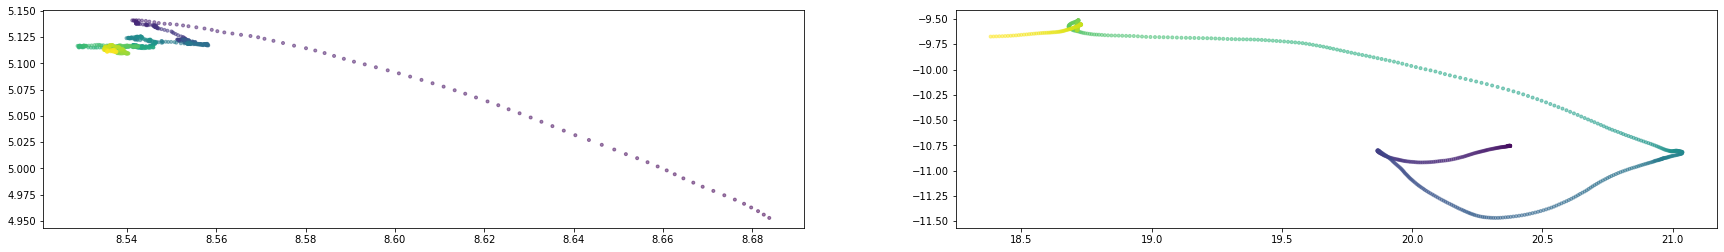

Z:/DATA/experiment_trackball_Optomotor/L22020/220814/sweeploom
['f2b_r_sloom' 'f2b_l_sloom']
[[0.4718936]
 [5.853936 ]]


In [194]:
fig, axes = plt.subplots(1,index_points.shape[0],figsize=(30,4),squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.scatter(x[ind,:],y[ind,:],c=np.arange(len(x[ind,:])), marker='.', alpha=0.5)
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

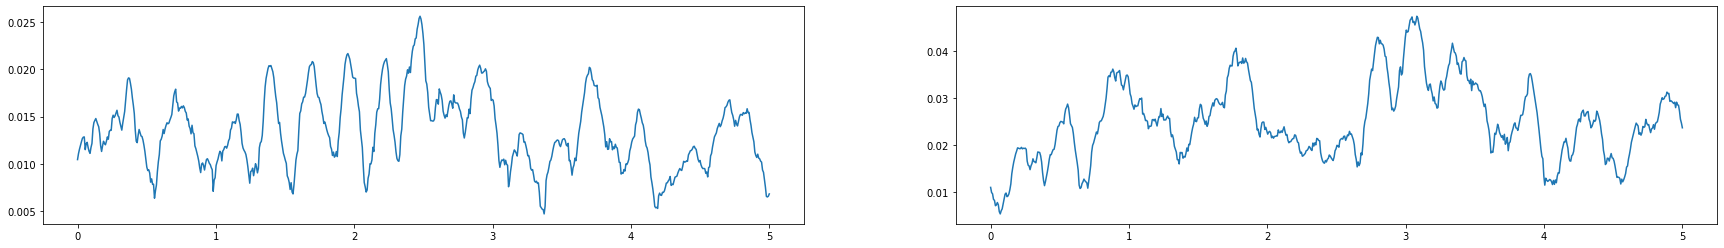

Z:/DATA/experiment_trackball_Optomotor/L22020/220814/sweeploom
['f2b_r_sloom' 'f2b_l_sloom']
[[0.4718936]
 [5.853936 ]]


In [195]:
fig, axes = plt.subplots(1,index_points.shape[0], figsize=(30,4), squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.plot(tp_tile[ind,:],velocity[ind,:])
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

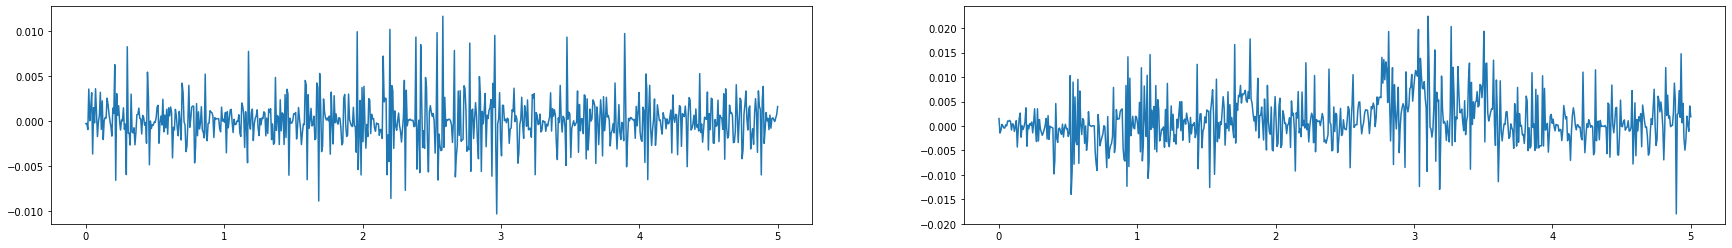

Z:/DATA/experiment_trackball_Optomotor/L22020/220814/sweeploom
['f2b_r_sloom' 'f2b_l_sloom']
[[0.4718936]
 [5.853936 ]]


In [196]:
fig, axes = plt.subplots(1,index_points.shape[0], figsize=(30,4), squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.plot(tp_tile[ind,:],velocity_x[ind,:])
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

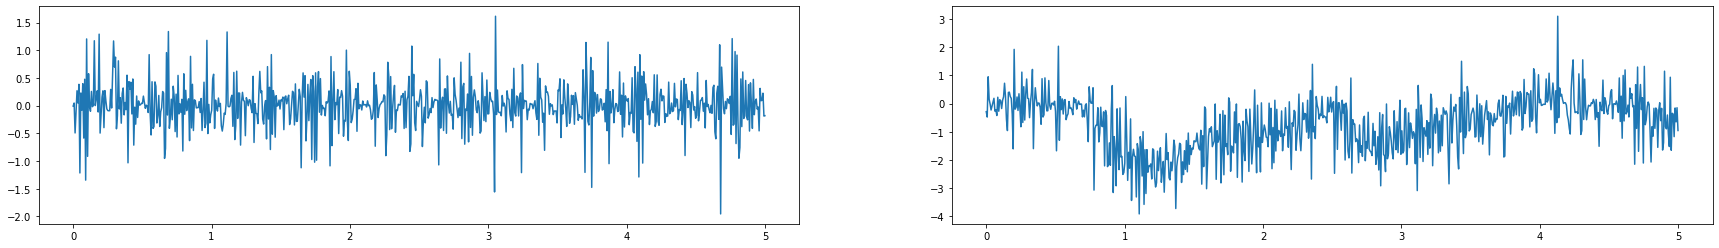

Z:/DATA/experiment_trackball_Optomotor/L22020/220814/sweeploom
['f2b_r_sloom' 'f2b_l_sloom']
[[0.4718936]
 [5.853936 ]]


In [197]:
fig, axes = plt.subplots(1,index_points.shape[0], figsize=(30,4), squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.plot(tp_tile[ind,:],velocity_z[ind,:])
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

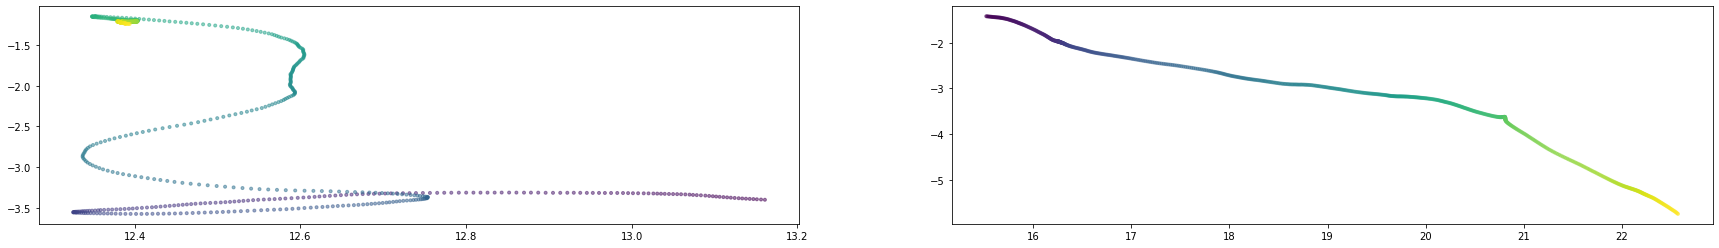

Z:/DATA/experiment_trackball_Optomotor/L22020/220814/sweeploom
['b2f_r_sloom' 'b2f_l_sloom']
[[4.212587]
 [8.640883]]


In [191]:
fig, axes = plt.subplots(1,index_points.shape[0],figsize=(30,4),squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.scatter(x[ind,:],y[ind,:],c=np.arange(len(x[ind,:])), marker='.', alpha=0.5)
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

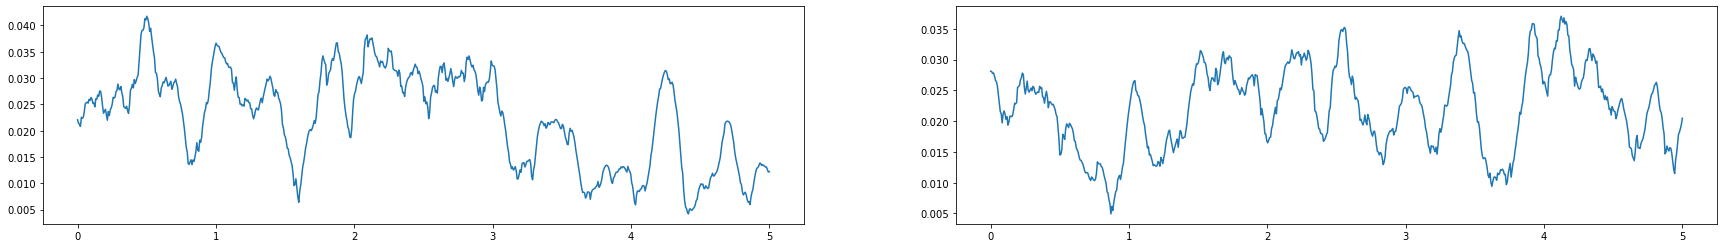

Z:/DATA/experiment_trackball_Optomotor/L22020/220814/sweeploom
['b2f_r_sloom' 'b2f_l_sloom']
[[4.212587]
 [8.640883]]


In [190]:
fig, axes = plt.subplots(1,index_points.shape[0], figsize=(30,4), squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.plot(tp_tile[ind,:],velocity[ind,:])
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

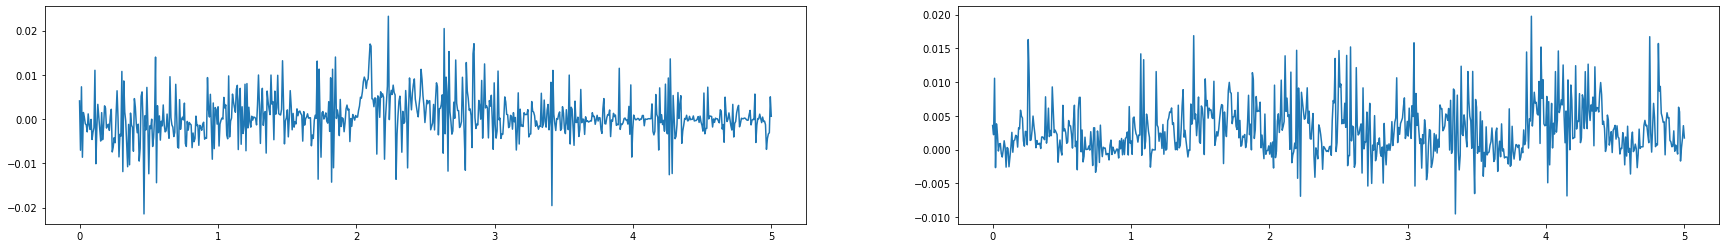

Z:/DATA/experiment_trackball_Optomotor/L22020/220814/sweeploom
['b2f_r_sloom' 'b2f_l_sloom']
[[4.212587]
 [8.640883]]


In [189]:
fig, axes = plt.subplots(1,index_points.shape[0], figsize=(30,4), squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.plot(tp_tile[ind,:],velocity_x[ind,:])
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

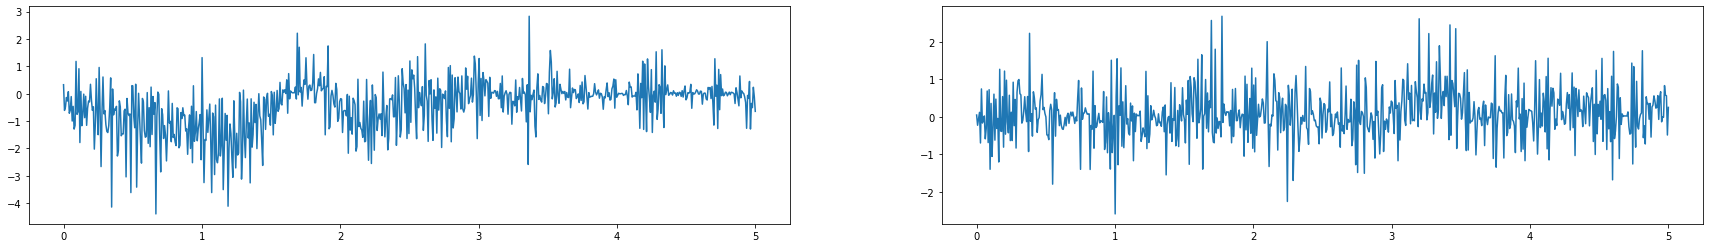

Z:/DATA/experiment_trackball_Optomotor/L22020/220814/sweeploom
['b2f_r_sloom' 'b2f_l_sloom']
[[4.212587]
 [8.640883]]


In [188]:
fig, axes = plt.subplots(1,index_points.shape[0], figsize=(30,4), squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.plot(tp_tile[ind,:],velocity_z[ind,:])
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

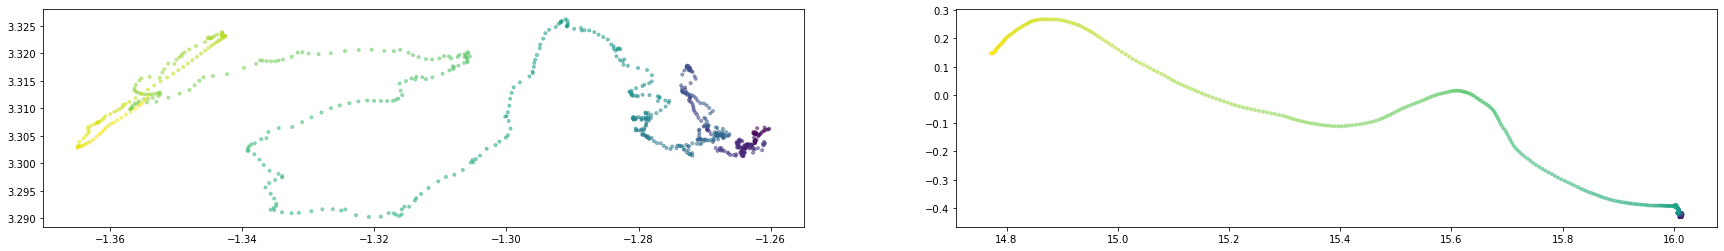

Z:/DATA/experiment_trackball_Optomotor/L22019/220814/sweeploom
['f2b_r_sloom' 'f2b_l_sloom']
[[0.44591585]
 [1.7978399 ]]


In [203]:
fig, axes = plt.subplots(1,index_points.shape[0],figsize=(30,4),squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.scatter(x[ind,:],y[ind,:],c=np.arange(len(x[ind,:])), marker='.', alpha=0.5)
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

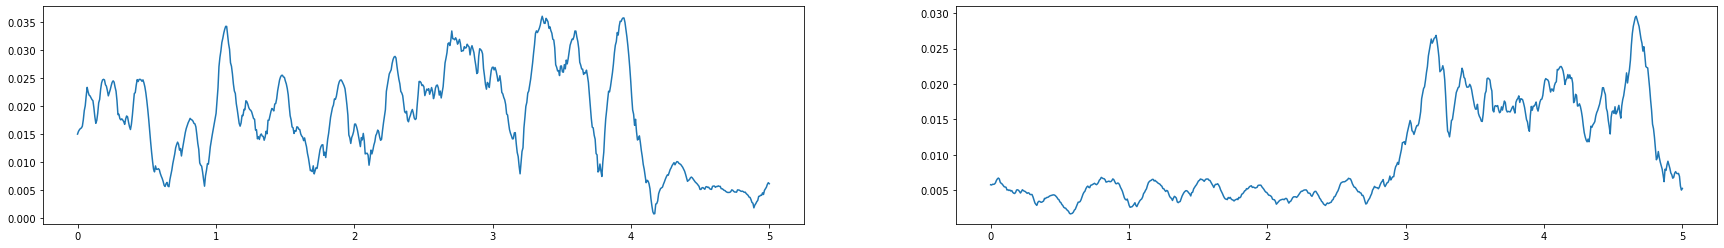

Z:/DATA/experiment_trackball_Optomotor/L22019/220814/sweeploom
['f2b_r_sloom' 'f2b_l_sloom']
[[0.44591585]
 [1.7978399 ]]


In [202]:
fig, axes = plt.subplots(1,index_points.shape[0], figsize=(30,4), squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.plot(tp_tile[ind,:],velocity[ind,:])
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

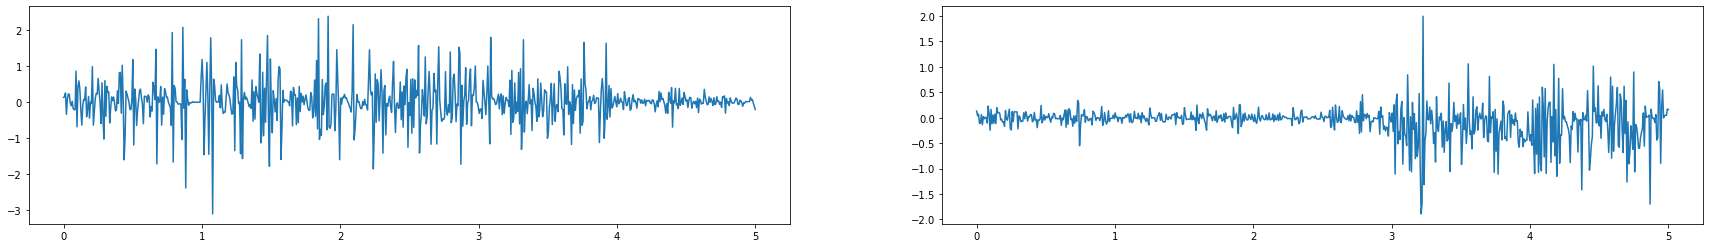

Z:/DATA/experiment_trackball_Optomotor/L22019/220814/sweeploom
['f2b_r_sloom' 'f2b_l_sloom']
[[0.44591585]
 [1.7978399 ]]


In [201]:
fig, axes = plt.subplots(1,index_points.shape[0], figsize=(30,4), squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.plot(tp_tile[ind,:],velocity_z[ind,:])
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

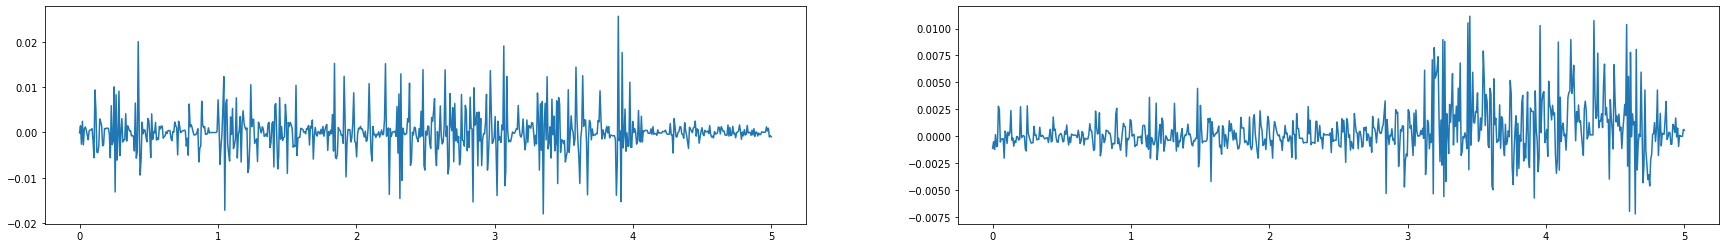

Z:/DATA/experiment_trackball_Optomotor/L22019/220814/sweeploom
['f2b_r_sloom' 'f2b_l_sloom']
[[0.44591585]
 [1.7978399 ]]


In [204]:
fig, axes = plt.subplots(1,index_points.shape[0], figsize=(30,4), squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.plot(tp_tile[ind,:],velocity_x[ind,:])
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)